# Importing Libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import roc_curve, auc
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings('ignore')

# Reading Data

In [4]:
df=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1053\\Data\\Code Dataset\\Non_Target_Lesion_Dataset.csv")

In [5]:
df['LSSLD_Change'].unique()

array([0, 1], dtype=int64)

In [6]:
df.columns

Index(['Unnamed: 0', 'SUBJID', 'AGE', 'SEXCD', 'TRTDOSE', 'TRTFREQ', 'TRT',
       'ACHEMO', 'ACHEMMCD', 'FCHEMOCD', 'B_LESNM', 'B_LESNMT', 'B_LESNMN',
       'B_METANM', 'PFSCR', 'INFREAC', 'BAWDOSE', 'OXCWDOSE', 'OXAWDOSE',
       'IRCDOSE', 'IRCWDOSE', 'FBCDOSE', 'FBCWDOSE', 'FICDOSE', 'FICWDOSE',
       'DUREXP', 'IRDSINTR', 'FBDURWK', 'FBDSINT', 'TRTDUR', 'CHANY5YR_N',
       'CHANY5YR_Y', 'CHREGPT_FLUOROURACIL', 'CHREGPT_FOLINIC ACID',
       'CHREGCLS_DETOXIFYING AGENTS FOR ANTINEOPLASTIC TREATMENT',
       'CHREGCLS_PYRIMIDINE ANALOGUES', 'DTHDY', 'DTCAUS', 'BIOPSITP',
       'BIOPTISB', 'BIOPTISS', 'BIOPSITP.1', 'BIOPSITM', 'ICSIGN', 'LDOSDSDY',
       'EOIP', 'EOTA', 'DSDOSDY', 'DSEOSYN', 'DSEOS', 'EOIPDY', 'EOBDY',
       'EOXIRDY', 'EOLEUDY', 'QTY', 'DOSE', 'ACTTRT_5-Fluorouracil',
       'ACTTRT_5-Fluorouracil 22 hour', 'ACTTRT_5-Fluorouracil 46 hour',
       'ACTTRT_5-Fluorouracil bolus', 'ACTTRT_Bevacizumab',
       'ACTTRT_Irinotecan', 'ACTTRT_Leucovorin', 'ACTTRT_Oxali

In [7]:
df.shape

(1694, 89)

In [8]:
df.head()

,Unnamed: 0,SUBJID,AGE,SEXCD,TRTDOSE,TRTFREQ,TRT,ACHEMO,ACHEMMCD,FCHEMOCD,...,SXANY5YR_N,SXANY5YR_Y,SXTYPE_Biopsy,SXTYPE_Laparoscopic,SXTYPE_Open,SXTYPE_Other,SXTYPE_Resection,SXTYPE_Surgery,VSSTRES,VSBLRES
0,4,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
1,5,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
2,6,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
3,7,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
4,16,249101002,72.0,M,0.0,Every 2 weeks,bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,1,0,0,1,1,1,88.514607,90.289888


# Feature Selection by Random Forest

In [10]:
df1=df

In [11]:
df1 = pd.get_dummies(df1, drop_first=True)

In [12]:
# Separate features and target
X = df1.drop('LSSLD_Change', axis=1)
y = df1['LSSLD_Change']

In [13]:
# Train a Random Forest model
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

RandomForestClassifier(random_state=42)

In [14]:
importances = rf.feature_importances_

In [16]:
# Create a dataframe for feature importances
feature_importances_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_importances_df = feature_importances_df.sort_values(by='Importance', ascending=False)

In [25]:
feature_importances_df.head(50)

,Feature,Importance
56,Percentage_LSSLD_Change,0.345233
55,LSSLD_Diff,0.121717
0,Unnamed: 0,0.058794
54,LSSLD,0.032240
21,IRDSINTR,0.024434
14,IRCDOSE,0.019394
53,DOSREFDY,0.017816
37,EOLEUDY,0.017475
19,FICWDOSE,0.017428
23,FBDSINT,0.017085


# Forming New Datasets

In [31]:
df=df[['SUBJID','LSNEWANY','LSSLD_Change','PFSCR','TRTDUR','OXAWDOSE','EOBDY','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','EOXIRDY','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
df.shape

(1694, 27)

In [33]:
df.head()

,SUBJID,LSNEWANY,LSSLD_Change,PFSCR,TRTDUR,OXAWDOSE,EOBDY,OXCWDOSE,LBORRESN,LDOSDSDY,...,FBCDOSE,VSBLRES,FICWDOSE,DOSE,EOXIRDY,B_LESNM,B_LESNMN,B_LESNMT,IRCDOSE,IRDSINTR
0,249101001,N,0,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
1,249101001,N,0,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
2,249101001,Y,0,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
3,249101001,Y,0,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
4,249101002,N,0,1.0,365.0,90.790640,365.0,907.906402,53.946474,365.0,...,9200.0,90.289888,24059.109235,708.743802,197.0,101.0,99.0,2.0,NaN,NaN


In [35]:
dfnew=df.drop_duplicates(keep='first')
dfnew.shape

(1030, 27)

In [37]:
result1=dfnew

# Logistic Regression

In [40]:
result1.shape

(1030, 27)

In [42]:
result1.fillna(0, inplace=True)

In [44]:
result1['LSNEWANY'] = result1['LSNEWANY'].astype('category').cat.codes

In [46]:
X=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
y=result1[['LSSLD_Change']]

In [48]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [50]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [52]:
model11= LogisticRegression()

In [54]:
result1['LSSLD_Change'].unique()

array([0, 1], dtype=int64)

In [56]:
model11.fit(X_train_scaled, y_train)

LogisticRegression()

In [58]:
y_pred = model11.predict(X_test_scaled)

In [64]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9903


In [66]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[204   0]
 [  2   0]]


In [68]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       204
           1       0.00      0.00      0.00         2

    accuracy                           0.99       206
   macro avg       0.50      0.50      0.50       206
weighted avg       0.98      0.99      0.99       206



In [70]:
y_train_pred = model11.predict(X_train_scaled)

y_test_pred = model11.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

if train_accuracy > test_accuracy:
    print("\nPotential Overfitting Detected!")
else:
    print("\nNo Overfitting Detected!")

Training Accuracy: 0.9903
Test Accuracy: 0.9903

No Overfitting Detected!


# Feature Importance

     Feature  Importance
3   OXAWDOSE   -0.887360
1      PFSCR    0.650820
7    VSSTRES    0.574581
4   OXCWDOSE    0.529798
11  LBSTRESN   -0.484723
0   LSNEWANY    0.444710
21   IRCDOSE    0.409789
10  FBCWDOSE    0.388114
5   LBORRESN   -0.355506
20  B_LESNMT   -0.274891
6   LDOSDSDY   -0.264870
2     TRTDUR   -0.264870
8     DUREXP   -0.259500
16  FICWDOSE   -0.238688
18   B_LESNM   -0.234966
19  B_LESNMN   -0.227220
17      DOSE   -0.205380
9    FBDSINT    0.200353
14   FBCDOSE    0.129312
22  IRDSINTR    0.098462
13   BAWDOSE   -0.069279
15   VSBLRES    0.031315
12   FICDOSE   -0.004342


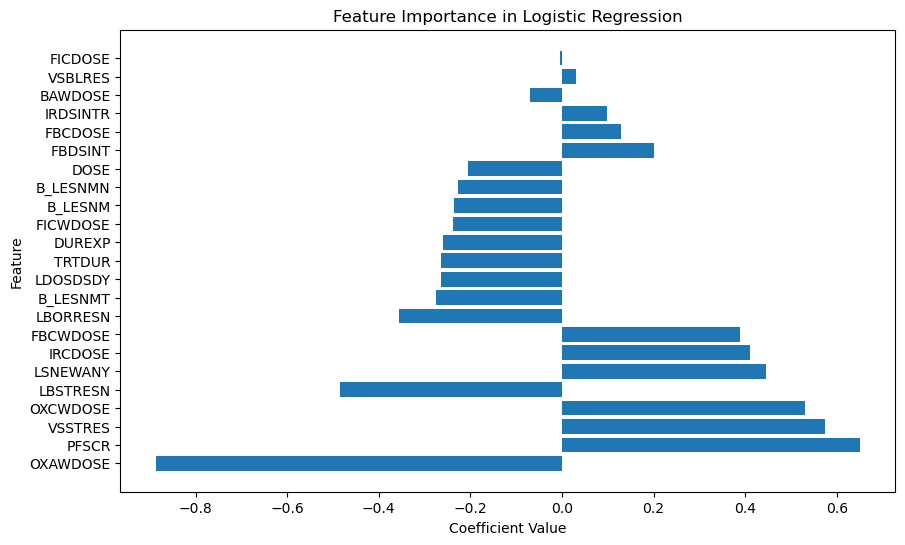

In [74]:
if len(model11.coef_) == 1:
    coefficients = model11.coef_[0]
else:
    coefficients = np.mean(model11.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# XGBoost Regression

In [76]:
import xgboost as xgb

In [78]:
features=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
target=result1[['LSSLD_Change']]

In [80]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

In [82]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, target, test_size=0.2, random_state=42)

In [84]:
# Initialize and fit the XGBoost model
model12 = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model12.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

In [86]:
y_pred = model12.predict(X_test)

In [88]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.9854
Confusion Matrix:
[[203   1]
 [  2   0]]
Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       204
           1       0.00      0.00      0.00         2

    accuracy                           0.99       206
   macro avg       0.50      0.50      0.50       206
weighted avg       0.98      0.99      0.98       206



# Feature Importance

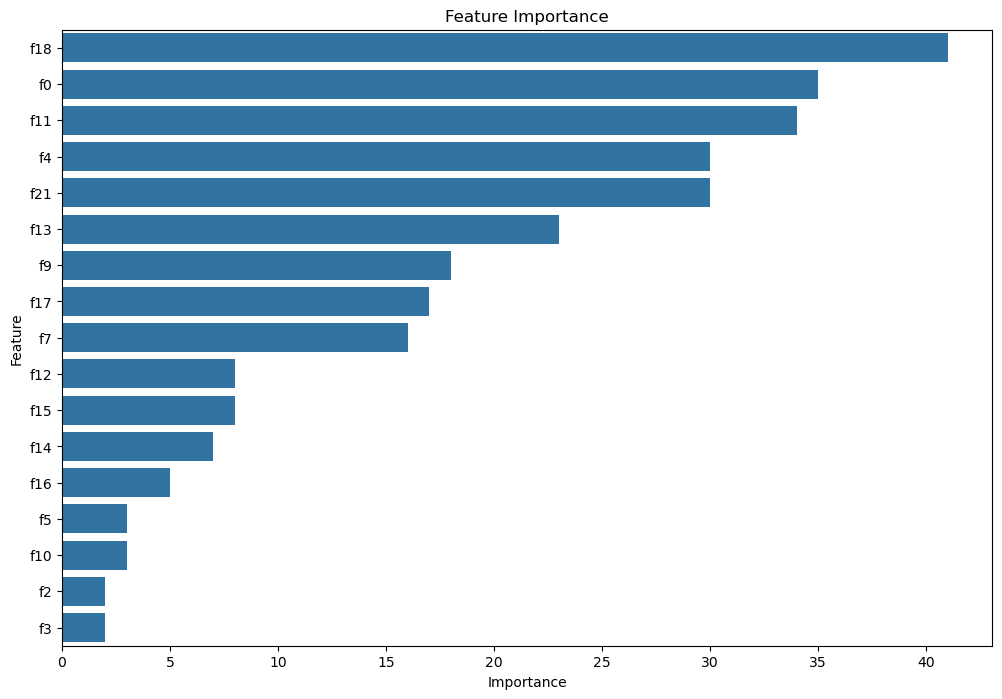

In [93]:
importances = model12.get_booster().get_score(importance_type='weight')
feature_importance = pd.DataFrame({
    'Feature': importances.keys(),
    'Importance': importances.values()
})

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance)
plt.title('Feature Importance')
plt.show()

# Regression with Linear,Decision Tree,Random Forest,Gadient Boosting,Support Vector and Neural Network

In [95]:
features=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
target=result1[['LSSLD_Change']]

In [97]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "Gradient Boosting": GradientBoostingRegressor(),
    "Support Vector Regression": make_pipeline(StandardScaler(), SVR()),
    "Neural Network": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000))
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Calculate Mean Squared Error and R² Score
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"{name} - Mean Squared Error: {mse}, R² Score: {r2}")


Linear Regression - Mean Squared Error: 0.00950986979211617, R² Score: 0.010880307602348371
Decision Tree - Mean Squared Error: 0.02669902912621359, R² Score: -1.7769607843137258
Random Forest - Mean Squared Error: 0.011922702383704289, R² Score: -0.24007793714430203
Gradient Boosting - Mean Squared Error: 0.01500846167574796, R² Score: -0.5610271560589228
Support Vector Regression - Mean Squared Error: 0.013627920307814845, R² Score: -0.41743731907458526
Neural Network - Mean Squared Error: 0.012880247714910207, R² Score: -0.3396720392890431


# ROC and AUC

In [100]:
X=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
y=result1[['LSSLD_Change']]

X, y = make_classification(n_samples=1000, n_features=20, 
                           n_informative=2, n_redundant=10, 
                           random_state=42)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [102]:
# Train a model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict probabilities
y_score = model.predict_proba(X_test)[:, 1]

# Compute ROC curve and ROC AUC
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

In [104]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 0.84


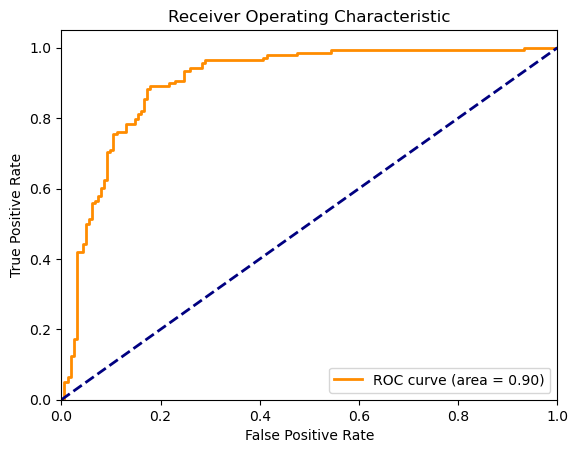

In [106]:
# Plot the ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

# KNN Model

In [117]:
X=result1[['LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
y=result1[['LSSLD_Change']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [119]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize the KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)

In [121]:
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [123]:
y_pred = knn.predict(X_test)

In [124]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f'Accuracy: {accuracy}')
print('Confusion Matrix:')
print(conf_matrix)
print('Classification Report:')
print(class_report)

Accuracy: 0.9902912621359223
Confusion Matrix:
[[204   0]
 [  2   0]]
Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       204
           1       0.00      0.00      0.00         2

    accuracy                           0.99       206
   macro avg       0.50      0.50      0.50       206
weighted avg       0.98      0.99      0.99       206



# Conclusion

# Features Considered for Prediction are
'LSNEWANY','PFSCR','TRTDUR','OXAWDOSE','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR'

# Regression Models

# Logistic Regression:
Accuracy: 0.9903

Confusion Matrix:

[[204   0]

 [  2   0]]
 
# XGBoost Regression:
Accuracy: 0.9854

Confusion Matrix:

[[203   1]

 [  2   0]]
 

# Linear Regression:
Mean Squared Error: 0.00950986979211617
R² Score: 0.010880307602348371


# Decision Tree:
Mean Squared Error: 0.02063106796116505
R² Score: -1.1458333333333335


# Random Forest:
Mean Squared Error: 0.011518353964401295
R² Score: -0.19802173733660156


# Gradient Boosting:
Mean Squared Error: 0.014776004573024047
R² Score: -0.5368493383844326


# Support Vector Regression:
Mean Squared Error: 0.013627920307814845
R² Score: -0.41743731907458526


# Neural Network:
Mean Squared Error: 0.013424516907689624
R² Score: -0.3962813713105806


# ROC and AUC
Accuracy: 0.84


# KNN Model:
Accuracy: 0.9902912621359223

Confusion Matrix:

[[204   0]

 [  2   0]]

Based on all these observation tell which is a better model considering confusion matrix also and which other models can we try for better prediction other than confusion matrix